# LSTM Direct Prediction Graph

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

def find_project_root():
    """Find the repository root when Jupyter is launched from inside the repository."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "Data Download").is_dir() and (candidate / "FCNN Direct Method").is_dir():
            return candidate
    raise FileNotFoundError(
        "Cannot locate the repository root containing 'Data Download' and the method folders."
    )


PROJECT_ROOT = find_project_root()
RAW_DATA_DIR = PROJECT_ROOT / "Data Download"
FIXED_DATA_DIR = PROJECT_ROOT / "fixed_data"
DATA_FILE = FIXED_DATA_DIR / "ercot_2021_2024_hourly.csv"
OUTPUT_DIR = PROJECT_ROOT / "fixed_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = PROJECT_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TIME_COLUMN = "time"
predictions = pd.read_excel(OUTPUT_DIR / "lstm_direct_net_load_predictions.xlsx")
required = {"time", "actual", "predict"}
if not required.issubset(predictions.columns):
    raise KeyError(f"Missing prediction columns: {sorted(required.difference(predictions.columns))}")
predictions["time"] = pd.to_datetime(predictions["time"], errors="raise")
predictions = predictions.sort_values("time").reset_index(drop=True)
predictions.head()


,time,actual,predict,error,absolute_error
0,2024-10-20 05:00:00,25361.962786,25319.601562,-42.361224,42.361224
1,2024-10-20 06:00:00,23383.175588,23505.826172,122.650584,122.650584
2,2024-10-20 07:00:00,22096.136331,22330.144531,234.008201,234.008201
3,2024-10-20 08:00:00,21250.184987,21323.945312,73.760325,73.760325
4,2024-10-20 09:00:00,21563.937474,20937.167969,-626.769505,626.769505


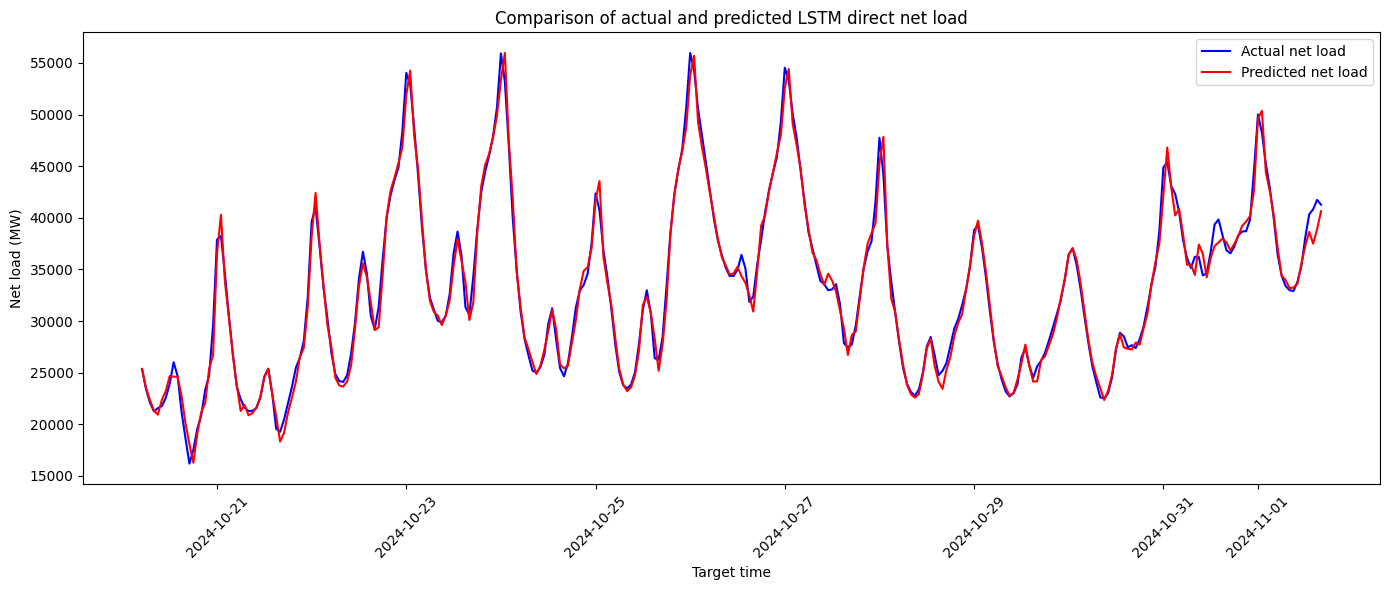

In [2]:
view = predictions.iloc[:min(300, len(predictions))].reset_index(drop=True)
sample_index = view.index.to_numpy()
paper_style = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": 9,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
}
with plt.rc_context(paper_style):
    fig, ax = plt.subplots(figsize=(5.5, 2.7))
    ax.plot(sample_index, view["actual"], color="#1f77b4", linewidth=0.9, label="Actual Net Load")
    ax.plot(sample_index, view["predict"], color="#ff7f0e", linewidth=0.9, label="Predicted Net Load")
    ax.set_xlabel("Sample Index")
    ax.set_ylabel("Net Load (MW)")
    ax.set_xticks(range(0, len(view) + 1, 50))
    ax.grid(True, linestyle="--", linewidth=0.55, color="#bfbfbf", alpha=0.65)
    ax.legend(loc="upper right", frameon=True, fancybox=False, edgecolor="#bfbfbf", framealpha=1.0)
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.0)
    ax.tick_params(direction="out", length=3.0, width=0.8, colors="black")
    fig.tight_layout(pad=0.5)
    figure_path = FIGURE_DIR / "Fig_10_LSTM_Direct_Actual_vs_Predicted.png"
    fig.savefig(figure_path, dpi=600, bbox_inches="tight")
    print("Saved figure:", figure_path)
    plt.show()
